In [ ]:
def f_burgers(u):
    return 0.5 * u**2

def df_burgers(u):
    return u                      # velocidad de la onda = derivada del flujo

def flujo_rusanov(f, df, ul, ur):
    a = np.maximum(np.abs(df(ul)), np.abs(df(ur)))      # velocidad máxima en la cara
    return 0.5 * (f(ul) + f(ur)) - 0.5 * a * (ur - ul)

def simular_general(f, df, u0, N=400, tiempos=(0.0, 0.5), cfl=0.8, L=1.0, borde="periodico"):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    u = u0(x)
    t = 0.0
    guardadas = {}
    for t_obj in tiempos:                                  # avanza hasta cada tiempo pedido
        while t < t_obj - 1e-12:
            dt = min(cfl * dx / np.max(np.abs(df(u))), t_obj - t)
            if borde == "periodico":
                up = np.concatenate(([u[-1]], u, [u[0]]))   # lo que sale por la derecha entra por la izquierda
            else:
                up = np.pad(u, 1, mode="edge")              # bordes abiertos
            F = flujo_rusanov(f, df, up[:-1], up[1:])
            u = u - dt / dx * (F[1:] - F[:-1])
            t += dt
        guardadas[t_obj] = u.copy()
    return x, guardadas

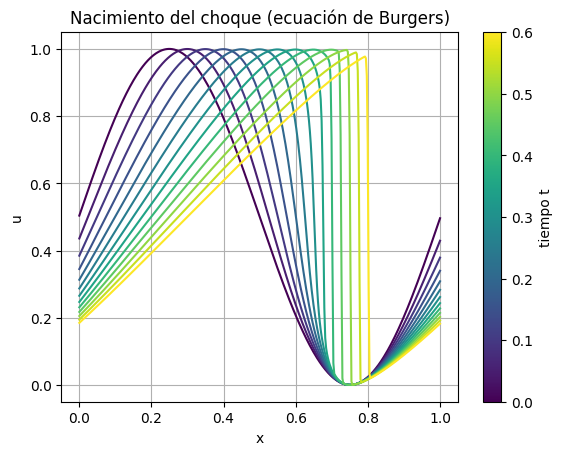

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def u0_seno(x):
    return 0.5 + 0.5 * np.sin(2 * np.pi * x)

tiempos = [0.0, 0.05,0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
x, sol = simular_general(f_burgers, df_burgers, u0_seno, tiempos=tiempos)

colores = plt.cm.viridis(np.linspace(0, 1, len(tiempos)))
for t, c in zip(tiempos, colores):
    plt.plot(x, sol[t], color=c)

barra = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(min(tiempos), max(tiempos)))
plt.colorbar(barra, ax=plt.gca(), label="tiempo t")

plt.xlabel("x"); plt.ylabel("u")
plt.title("Nacimiento del choque (ecuación de Burgers)")
plt.grid(True)
plt.show()

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

tiempos_anim = np.linspace(0, 0.8, 60)
x, sol = simular_general(f_burgers, df_burgers, u0_seno, tiempos=tiempos_anim)

fig, ax = plt.subplots()
linea, = ax.plot(x, sol[tiempos_anim[0]])
ax.set_ylim(-0.1, 1.1); ax.set_xlabel("x"); ax.set_ylabel("u")
titulo = ax.set_title("")

def cuadro(k):
    t = tiempos_anim[k]
    linea.set_ydata(sol[t])
    titulo.set_text(f"Burgers, t = {t:.2f}")
    return linea,

anim = FuncAnimation(fig, cuadro, frames=len(tiempos_anim), interval=80)
anim.save("burgers_seno.gif", writer=PillowWriter(fps=12))
plt.close()

from google.colab import files
files.download("burgers_seno.gif")              #Descarga auto

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>